### Handle Imbalanced Dataset

- 1000 datapts->900yes,100No for a classification problem
- to handle we use Upscaling and Downscaling
- Upscaling and Downscaling for only <b>training set not for test set</b>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
#reproducibility-set random seed
np.random.seed(123)
n_samples=1000
class_0_ratio=0.9
n_class_0=int(n_samples*class_0_ratio)
class_1_ratio=0.1
n_class_1=int(n_samples*class_1_ratio)
print(n_class_0)
print(n_class_1)

900
100


In [3]:
#create df with imbalanced dataset
class_0=pd.DataFrame({'feature_1':np.random.normal(loc=0,scale=1,size=n_class_0),'feature_2':np.random.normal(loc=0,scale=1,size=n_class_0),'target':[0]*n_class_0})
# 'target':[0]*n_class_0 ->generate values around 0
class_1=pd.DataFrame({'feature_1':np.random.normal(loc=2,scale=1,size=n_class_1),'feature_2':np.random.normal(loc=2,scale=1,size=n_class_1),'target':[1]*n_class_1})
# 'target':[0]*n_class_0 ->generate values around 1

In [4]:
#concatenate both classes data for a whole dataset
df=pd.concat([class_0,class_1]).reset_index(drop=True)
print(df.sample(5))
df['target'].value_counts()

     feature_1  feature_2  target
382  -1.305786  -0.366811       0
879   0.997957   1.482163       0
37    0.688223   0.670512       0
98    0.379401   0.470264       0
990   3.063905   0.919587       1


target
0    900
1    100
Name: count, dtype: int64

#### Upsampling/Oversampling
- Minority Data will be increased on using Upsampling
- whole data size increases
- on resampling-with replacement
- may cause of overfitting due to duplicate samples on replacement
- used for smaller Datasets

In [5]:
df_minority=df[df['target']==1]
df_majority=df[df['target']==0]

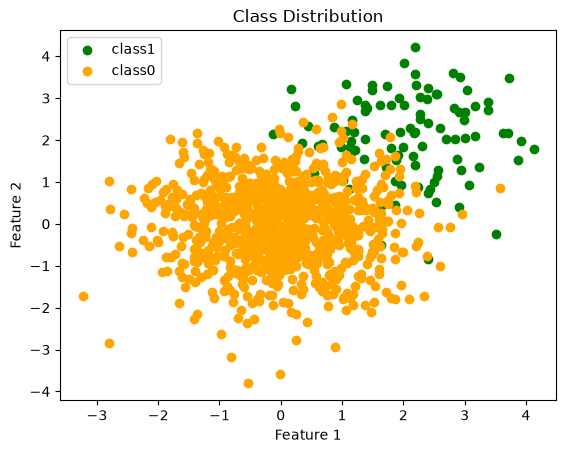

In [6]:
plt.scatter(df_minority['feature_1'],df_minority['feature_2'],color='green',label='class1')
plt.scatter(df_majority['feature_1'],df_majority['feature_2'],color='orange',label='class0')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Class Distribution')
plt.legend()
plt.show()

#### Resampling - try to equalize with majority

In [7]:
from sklearn.utils import resample
df_minority_upsampled=resample(df_minority,replace=True,n_samples=len(df_majority),random_state=42)
print(df_minority_upsampled.head())
df_minority_upsampled.sample(5)

     feature_1  feature_2  target
951   1.125854   1.843917       1
992   2.196570   1.397425       1
914   1.932170   2.998053       1
971   2.272825   3.034197       1
960   2.870056   1.550485       1


,feature_1,feature_2,target
929,0.605291,1.862623,1
984,1.712216,1.346491,1
957,1.364350,1.535966,1
939,2.304062,1.858166,1
918,1.630825,-0.503161,1


In [8]:
df_upsampled=pd.concat([df_majority,df_minority_upsampled])
df_upsampled['target'].value_counts()

target
0    900
1    900
Name: count, dtype: int64

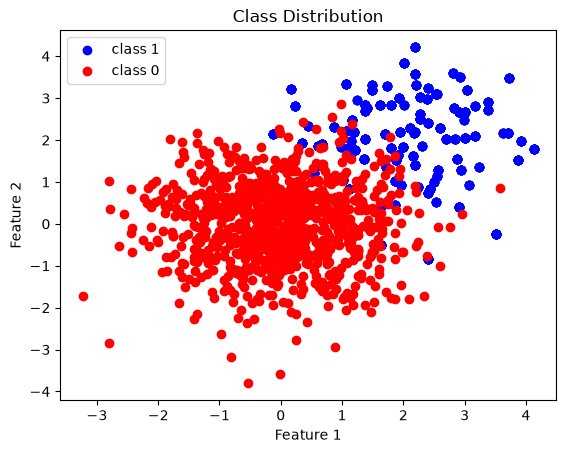

In [9]:
plt.scatter(df_minority_upsampled['feature_1'],df_minority_upsampled['feature_2'],color='blue',label='class 1')
plt.scatter(df_majority['feature_1'],df_majority['feature_2'],color='red',label='class 0')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Class Distribution')
plt.legend()
plt.show()

#### Downsampling/UnderSampling
- majority class data size decreases
- whole data set decreases
- on resampling without replacement
- may loose useful info
- suited for larger dataset

In [10]:
#separate majority & minority classes
class_0=df[df['target']==0]
class_1=df[df['target']==1]
print(f"0:{len(class_0)}")
print(f"1:{len(class_1)}")
class_0_downsampled=resample(class_0,replace=False,n_samples=len(class_1),random_state=42)
#combine classes
df_downsampled=pd.concat([class_0_downsampled,class_1])
print(df_downsampled['target'].value_counts())

0:900
1:100
target
0    100
1    100
Name: count, dtype: int64


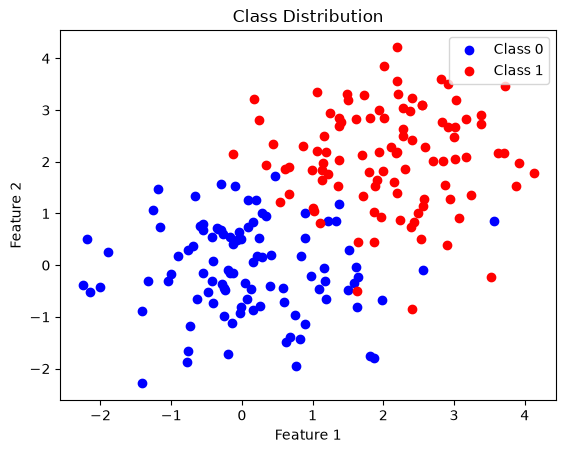

In [11]:
plt.scatter(class_0_downsampled['feature_1'],
            class_0_downsampled['feature_2'],
            color='blue',
            label='Class 0')

plt.scatter(class_1['feature_1'],
            class_1['feature_2'],
            color='red',
            label='Class 1')

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Class Distribution')
plt.legend()
plt.show()

#### Upsampling Technique
- <b>SMOTE(Synthetic minority Oversampling Technique)</b>

In [12]:
from sklearn.datasets import make_classification

X,y=make_classification(n_samples=1000,n_features=2,n_redundant=0,n_clusters_per_class=1,random_state=12,weights=[0.90])


In [13]:
df1=pd.DataFrame(X,columns=['f1','f2'])
df2=pd.DataFrame(y,columns=['target'])
final_df=pd.concat([df1,df2],axis=1)
print(final_df.head())
print(f"X:{len(X)}")
print(f"y:{len(y)}")

         f1        f2  target
0 -0.762898 -0.706808       0
1 -1.075436 -1.051162       0
2 -0.610115 -0.909802       0
3 -2.023284 -0.428945       1
4 -0.812921 -1.316206       0
X:1000
y:1000


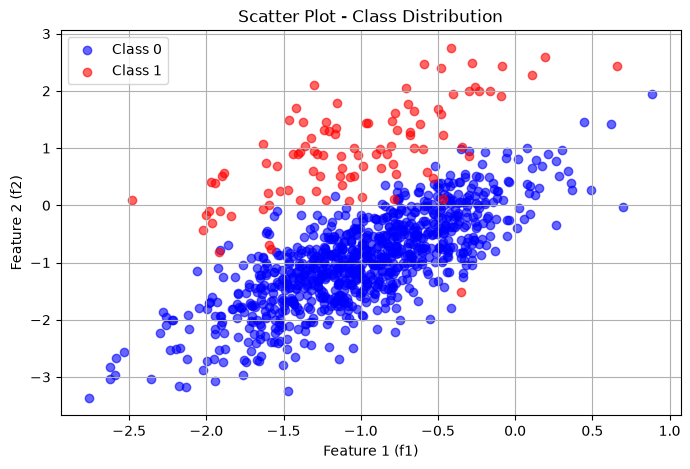

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Class 0
plt.scatter(
    final_df[final_df['target'] == 0]['f1'],
    final_df[final_df['target'] == 0]['f2'],
    color='blue',
    label='Class 0',
    alpha=0.6
)

# Class 1
plt.scatter(
    final_df[final_df['target'] == 1]['f1'],
    final_df[final_df['target'] == 1]['f2'],
    color='red',
    label='Class 1',
    alpha=0.6
)

plt.xlabel('Feature 1 (f1)')
plt.ylabel('Feature 2 (f2)')
plt.title('Scatter Plot - Class Distribution')

plt.legend()
plt.grid(True)
plt.show()

In [15]:
#!pip install imblearn


In [16]:
from imblearn.over_sampling import SMOTE
oversample=SMOTE()
X,y=oversample.fit_resample(final_df[['f1','f2']],final_df['target'])
print(X.shape)
print(y.shape)
print(y==0)
print(y[y==0])

(1800, 2)
(1800,)
0        True
1        True
2        True
3       False
4        True
        ...  
1795    False
1796    False
1797    False
1798    False
1799    False
Name: target, Length: 1800, dtype: bool
0      0
1      0
2      0
4      0
5      0
      ..
995    0
996    0
997    0
998    0
999    0
Name: target, Length: 900, dtype: int64


In [17]:
print(len(y[y==0]))
print(len(y[y==1]))

900
900


### 5 number summary and box plots

In [18]:
lst_marks=[45,32,56,75,89,54,32,89,90,87,67,54,45,98,99,67,74]
minimum,q1,median,q3,maximum=np.quantile(lst_marks,[0,0.25,0.50,0.75,1.00])
minimum,q1,median,q3,maximum

(np.float64(32.0),
 np.float64(54.0),
 np.float64(67.0),
 np.float64(89.0),
 np.float64(99.0))

In [19]:
lst_marks.describe

AttributeError: 'list' object has no attribute 'describe'

In [ ]:
l=pd.DataFrame({"l1":[45,32,56,75,89,54,32,89,90,87,67,54,45,98,99,67,74]})
print(l)

In [ ]:
print(type(l))

In [ ]:
l.describe()

In [ ]:
IQR=q3-q1
print(IQR)

In [20]:
lower_fence=q1-1.5*(IQR)
higher_fence=q3+1.5*(IQR)
print(lower_fence)
print(higher_fence)

NameError: name 'IQR' is not defined

- >1.5 and <141.5 values are outliers

In [21]:
sns.boxplot(l)

NameError: name 'l' is not defined

In [ ]:
outliers_list=pd.DataFrame({"l2":[-200,-100,45,34,56,78,89,180,490]})
sns.boxplot(outliers_list)

- outliers are represented as circles

#### Data Encoding
- Nominal/OHE Encoding: categorical->numerical(binary vector)
- Label/Ordinal Encoding: Categorical->ordered Numbers
- Target Guided Ordinal Encoding: encode categorical variiables relation with target variables

### Nominal/OHE Encoding:
- egs:red:[1,0,0]
  green:[0,1,0]
  blue:[0,0,1]
- Disadv: for a dataset of more than 10 colors which have more zeroes and ones it would result in overfitting and leads to Sparse matrix

In [22]:
from sklearn.preprocessing import OneHotEncoder

df=pd.DataFrame({'color':['red','blue','green','green','red','blue']})
df.head()

,color
0,red
1,blue
2,green
3,green
4,red


In [23]:
#create an instance for One hot encoder
encoder=OneHotEncoder()

In [24]:
# perform fit and transform
encoder.fit_transform(df[['color']])

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 6 stored elements and shape (6, 3)>

In [25]:
# perform fit and transform
encoded=encoder.fit_transform(df[['color']]).toarray()
#sorting happened by alphabetical order of colors
#blue,red,green,green,blue,red
print(encoded)

[[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]


In [26]:
encoder_df=pd.DataFrame(encoded,columns=encoder.get_feature_names_out())
encoder_df

,color_blue,color_green,color_red
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,1.0,0.0
3,0.0,1.0,0.0
4,0.0,0.0,1.0
5,1.0,0.0,0.0


In [27]:
#for new data
encoder.transform([['blue']]).toarray()

C:\Users\rushi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but OneHotEncoder was fitted with feature names
  warnings.warn(


array([[1., 0., 0.]])

In [28]:
pd.concat([df,encoder_df],axis=1)

,color,color_blue,color_green,color_red
0,red,0.0,0.0,1.0
1,blue,1.0,0.0,0.0
2,green,0.0,1.0,0.0
3,green,0.0,1.0,0.0
4,red,0.0,0.0,1.0
5,blue,1.0,0.0,0.0


In [29]:
df=sns.load_dataset('tips')
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [30]:
df['time'].unique()

['Dinner', 'Lunch']
Categories (2, str): ['Lunch', 'Dinner']

In [31]:
df['sex'].unique()

['Female', 'Male']
Categories (2, str): ['Male', 'Female']

In [32]:
from sklearn.preprocessing import OneHotEncoder
encoder=OneHotEncoder()
encoded_sex=encoder.fit_transform(df[['sex']]).toarray()
encoded_smoker=encoder.fit_transform(df[['smoker']]).toarray()

In [33]:
encoder_sex=pd.DataFrame(encoded_sex,columns=encoder.get_feature_names_out())
encoder_sex

,smoker_No,smoker_Yes
0,1.0,0.0
1,0.0,1.0
2,0.0,1.0
3,0.0,1.0
4,1.0,0.0
...,...,...
239,0.0,1.0
240,1.0,0.0
241,0.0,1.0
242,0.0,1.0


In [34]:
encoder_smoker=pd.DataFrame(encoded_smoker,columns=encoder.get_feature_names_out())
encoder_smoker

,smoker_No,smoker_Yes
0,1.0,0.0
1,1.0,0.0
2,1.0,0.0
3,1.0,0.0
4,1.0,0.0
...,...,...
239,1.0,0.0
240,0.0,1.0
241,0.0,1.0
242,1.0,0.0


### Label Encoding
- a unique value to each category
- red -1,green-2,blue-3

In [35]:
from sklearn.preprocessing import LabelEncoder

df=pd.DataFrame({'color':['red','green','blue']})
df.head()

,color
0,red
1,green
2,blue


In [36]:
lbl_encoder=LabelEncoder()
lbl_encoder.fit_transform(df['color'])

array([2, 1, 0])

In [37]:
print(lbl_encoder.transform(['red']))
print(lbl_encoder.transform(['green']))
lbl_encoder.transform(['blue'])

[2]
[1]


array([0])

### Ordinal Encoding
- every category is assigned a numerical value based on its position order
- high-1,low-0

In [38]:
from sklearn.preprocessing import OrdinalEncoder
df=pd.DataFrame({"size":['small','medium','large','medium','small','large']})
encoder=OrdinalEncoder(categories=[['small','medium','large']])
print(encoder.fit_transform(df[['size']]))
encoder.transform([['small']])

[[0.]
 [1.]
 [2.]
 [1.]
 [0.]
 [2.]]


C:\Users\rushi\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but OrdinalEncoder was fitted with feature names
  warnings.warn(


array([[0.]])

### Target Guided Ordinal Encoding

In [39]:
df=pd.DataFrame({'city':['New york','London','Paris','Tokyo','New york','Paris'],'price':[200,150,300,250,180,320]})
df

,city,price
0,New york,200
1,London,150
2,Paris,300
3,Tokyo,250
4,New york,180
5,Paris,320


In [40]:
df.groupby('city')['price'].mean()

city
London      150.0
New york    190.0
Paris       310.0
Tokyo       250.0
Name: price, dtype: float64

In [41]:
mean_price=df.groupby('city')['price'].mean().to_dict()
mean_price

{'London': 150.0, 'New york': 190.0, 'Paris': 310.0, 'Tokyo': 250.0}

In [42]:
df['city_encoded']=df['city'].map(mean_price)
df

,city,price,city_encoded
0,New york,200,190.0
1,London,150,150.0
2,Paris,300,310.0
3,Tokyo,250,250.0
4,New york,180,190.0
5,Paris,320,310.0


In [43]:
df[['price','city_encoded']]

,price,city_encoded
0,200,190.0
1,150,150.0
2,300,310.0
3,250,250.0
4,180,190.0
5,320,310.0


#### EDA on Red Wine Dataset

In [44]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\rushi\OneDrive\Documents\Machine_Learning\ML-Learnings
['.git', '.ipynb_checkpoints', 'env.txt', 'flight_price.xlsx', 'Untitled.ipynb', 'wineQualityInfo.txt', 'wineQualityReds.csv']


In [45]:
df=pd.read_csv('wineQualityReds.csv')
df.shape

(1599, 13)

In [46]:
df.describe()

,Unnamed: 0,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,800.000000,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,461.735855,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,1.000000,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,400.500000,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,800.000000,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,1199.500000,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,1599.000000,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [47]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            1599 non-null   int64  
 1   fixed.acidity         1599 non-null   float64
 2   volatile.acidity      1599 non-null   float64
 3   citric.acid           1599 non-null   float64
 4   residual.sugar        1599 non-null   float64
 5   chlorides             1599 non-null   float64
 6   free.sulfur.dioxide   1599 non-null   float64
 7   total.sulfur.dioxide  1599 non-null   float64
 8   density               1599 non-null   float64
 9   pH                    1599 non-null   float64
 10  sulphates             1599 non-null   float64
 11  alcohol               1599 non-null   float64
 12  quality               1599 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 162.5 KB


In [48]:
df['quality'].unique()

array([5, 6, 7, 4, 8, 3])

In [49]:
df.isnull().sum()

Unnamed: 0              0
fixed.acidity           0
volatile.acidity        0
citric.acid             0
residual.sugar          0
chlorides               0
free.sulfur.dioxide     0
total.sulfur.dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [50]:
df[df.duplicated()]

,Unnamed: 0,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality


In [51]:
df.drop_duplicates(inplace=True)

In [52]:
df.corr()

,Unnamed: 0,fixed.acidity,volatile.acidity,citric.acid,residual.sugar,chlorides,free.sulfur.dioxide,total.sulfur.dioxide,density,pH,sulphates,alcohol,quality
Unnamed: 0,1.000000,-0.268484,-0.008815,-0.153551,-0.031261,-0.119869,0.090480,-0.117850,-0.368372,0.136005,-0.125307,0.245123,0.066453
fixed.acidity,-0.268484,1.000000,-0.256131,0.671703,0.114777,0.093705,-0.153794,-0.113181,0.668047,-0.682978,0.183006,-0.061668,0.124052
volatile.acidity,-0.008815,-0.256131,1.000000,-0.552496,0.001918,0.061298,-0.010504,0.076470,0.022026,0.234937,-0.260987,-0.202288,-0.390558
citric.acid,-0.153551,0.671703,-0.552496,1.000000,0.143577,0.203823,-0.060978,0.035533,0.364947,-0.541904,0.312770,0.109903,0.226373
residual.sugar,-0.031261,0.114777,0.001918,0.143577,1.000000,0.055610,0.187049,0.203028,0.355283,-0.085652,0.005527,0.042075,0.013732
chlorides,-0.119869,0.093705,0.061298,0.203823,0.055610,1.000000,0.005562,0.047400,0.200632,-0.265026,0.371260,-0.221141,-0.128907
free.sulfur.dioxide,0.090480,-0.153794,-0.010504,-0.060978,0.187049,0.005562,1.000000,0.667666,-0.021946,0.070377,0.051658,-0.069408,-0.050656
total.sulfur.dioxide,-0.117850,-0.113181,0.076470,0.035533,0.203028,0.047400,0.667666,1.000000,0.071269,-0.066495,0.042947,-0.205654,-0.185100
density,-0.368372,0.668047,0.022026,0.364947,0.355283,0.200632,-0.021946,0.071269,1.000000,-0.341699,0.148506,-0.496180,-0.174919
pH,0.136005,-0.682978,0.234937,-0.541904,-0.085652,-0.265026,0.070377,-0.066495,-0.341699,1.000000,-0.196648,0.205633,-0.057731


<Axes: >

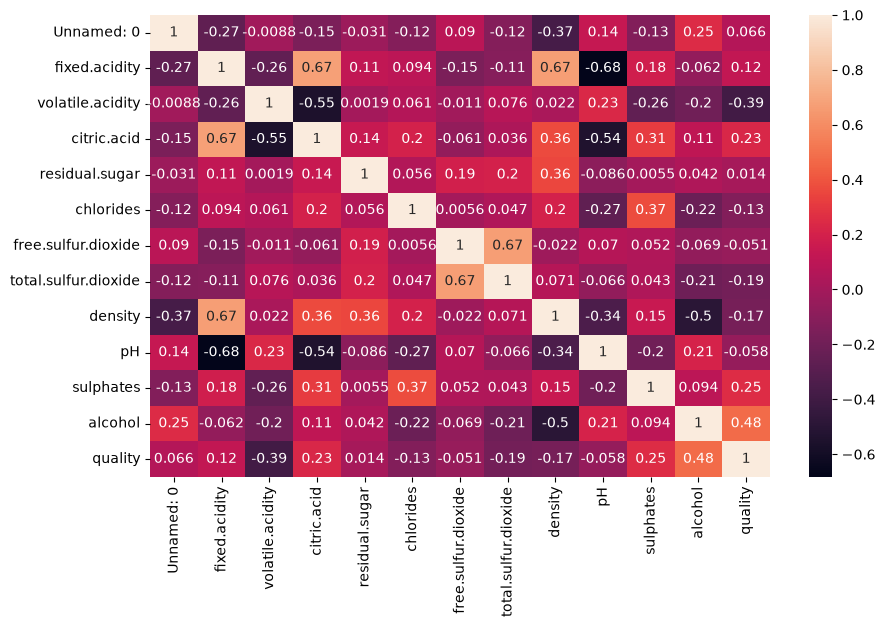

In [53]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True)

In [54]:
df['quality'].value_counts()

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64

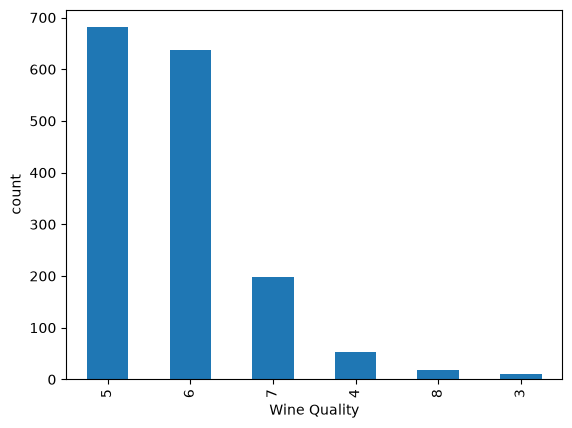

In [55]:
df['quality'].value_counts().plot(kind='bar')
plt.xlabel('Wine Quality')
plt.ylabel('count')
plt.show()

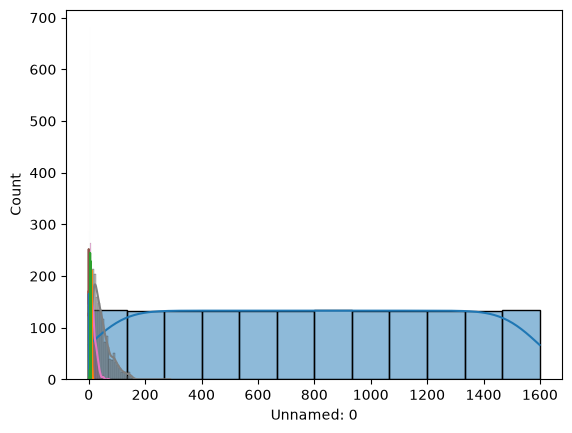

In [56]:
for column in df.columns:
    sns.histplot(df[column],kde=True)

<Axes: xlabel='alcohol', ylabel='Count'>

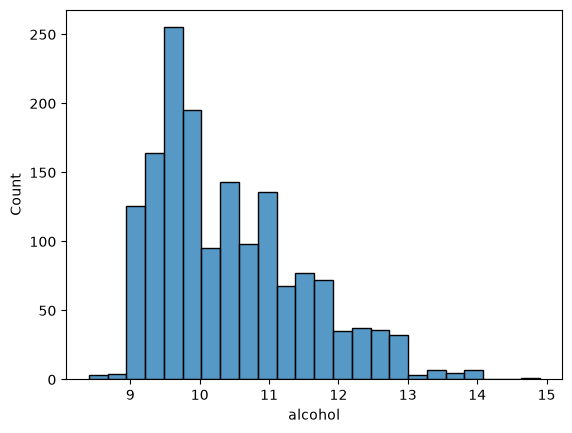

In [57]:
sns.histplot(df['alcohol'])

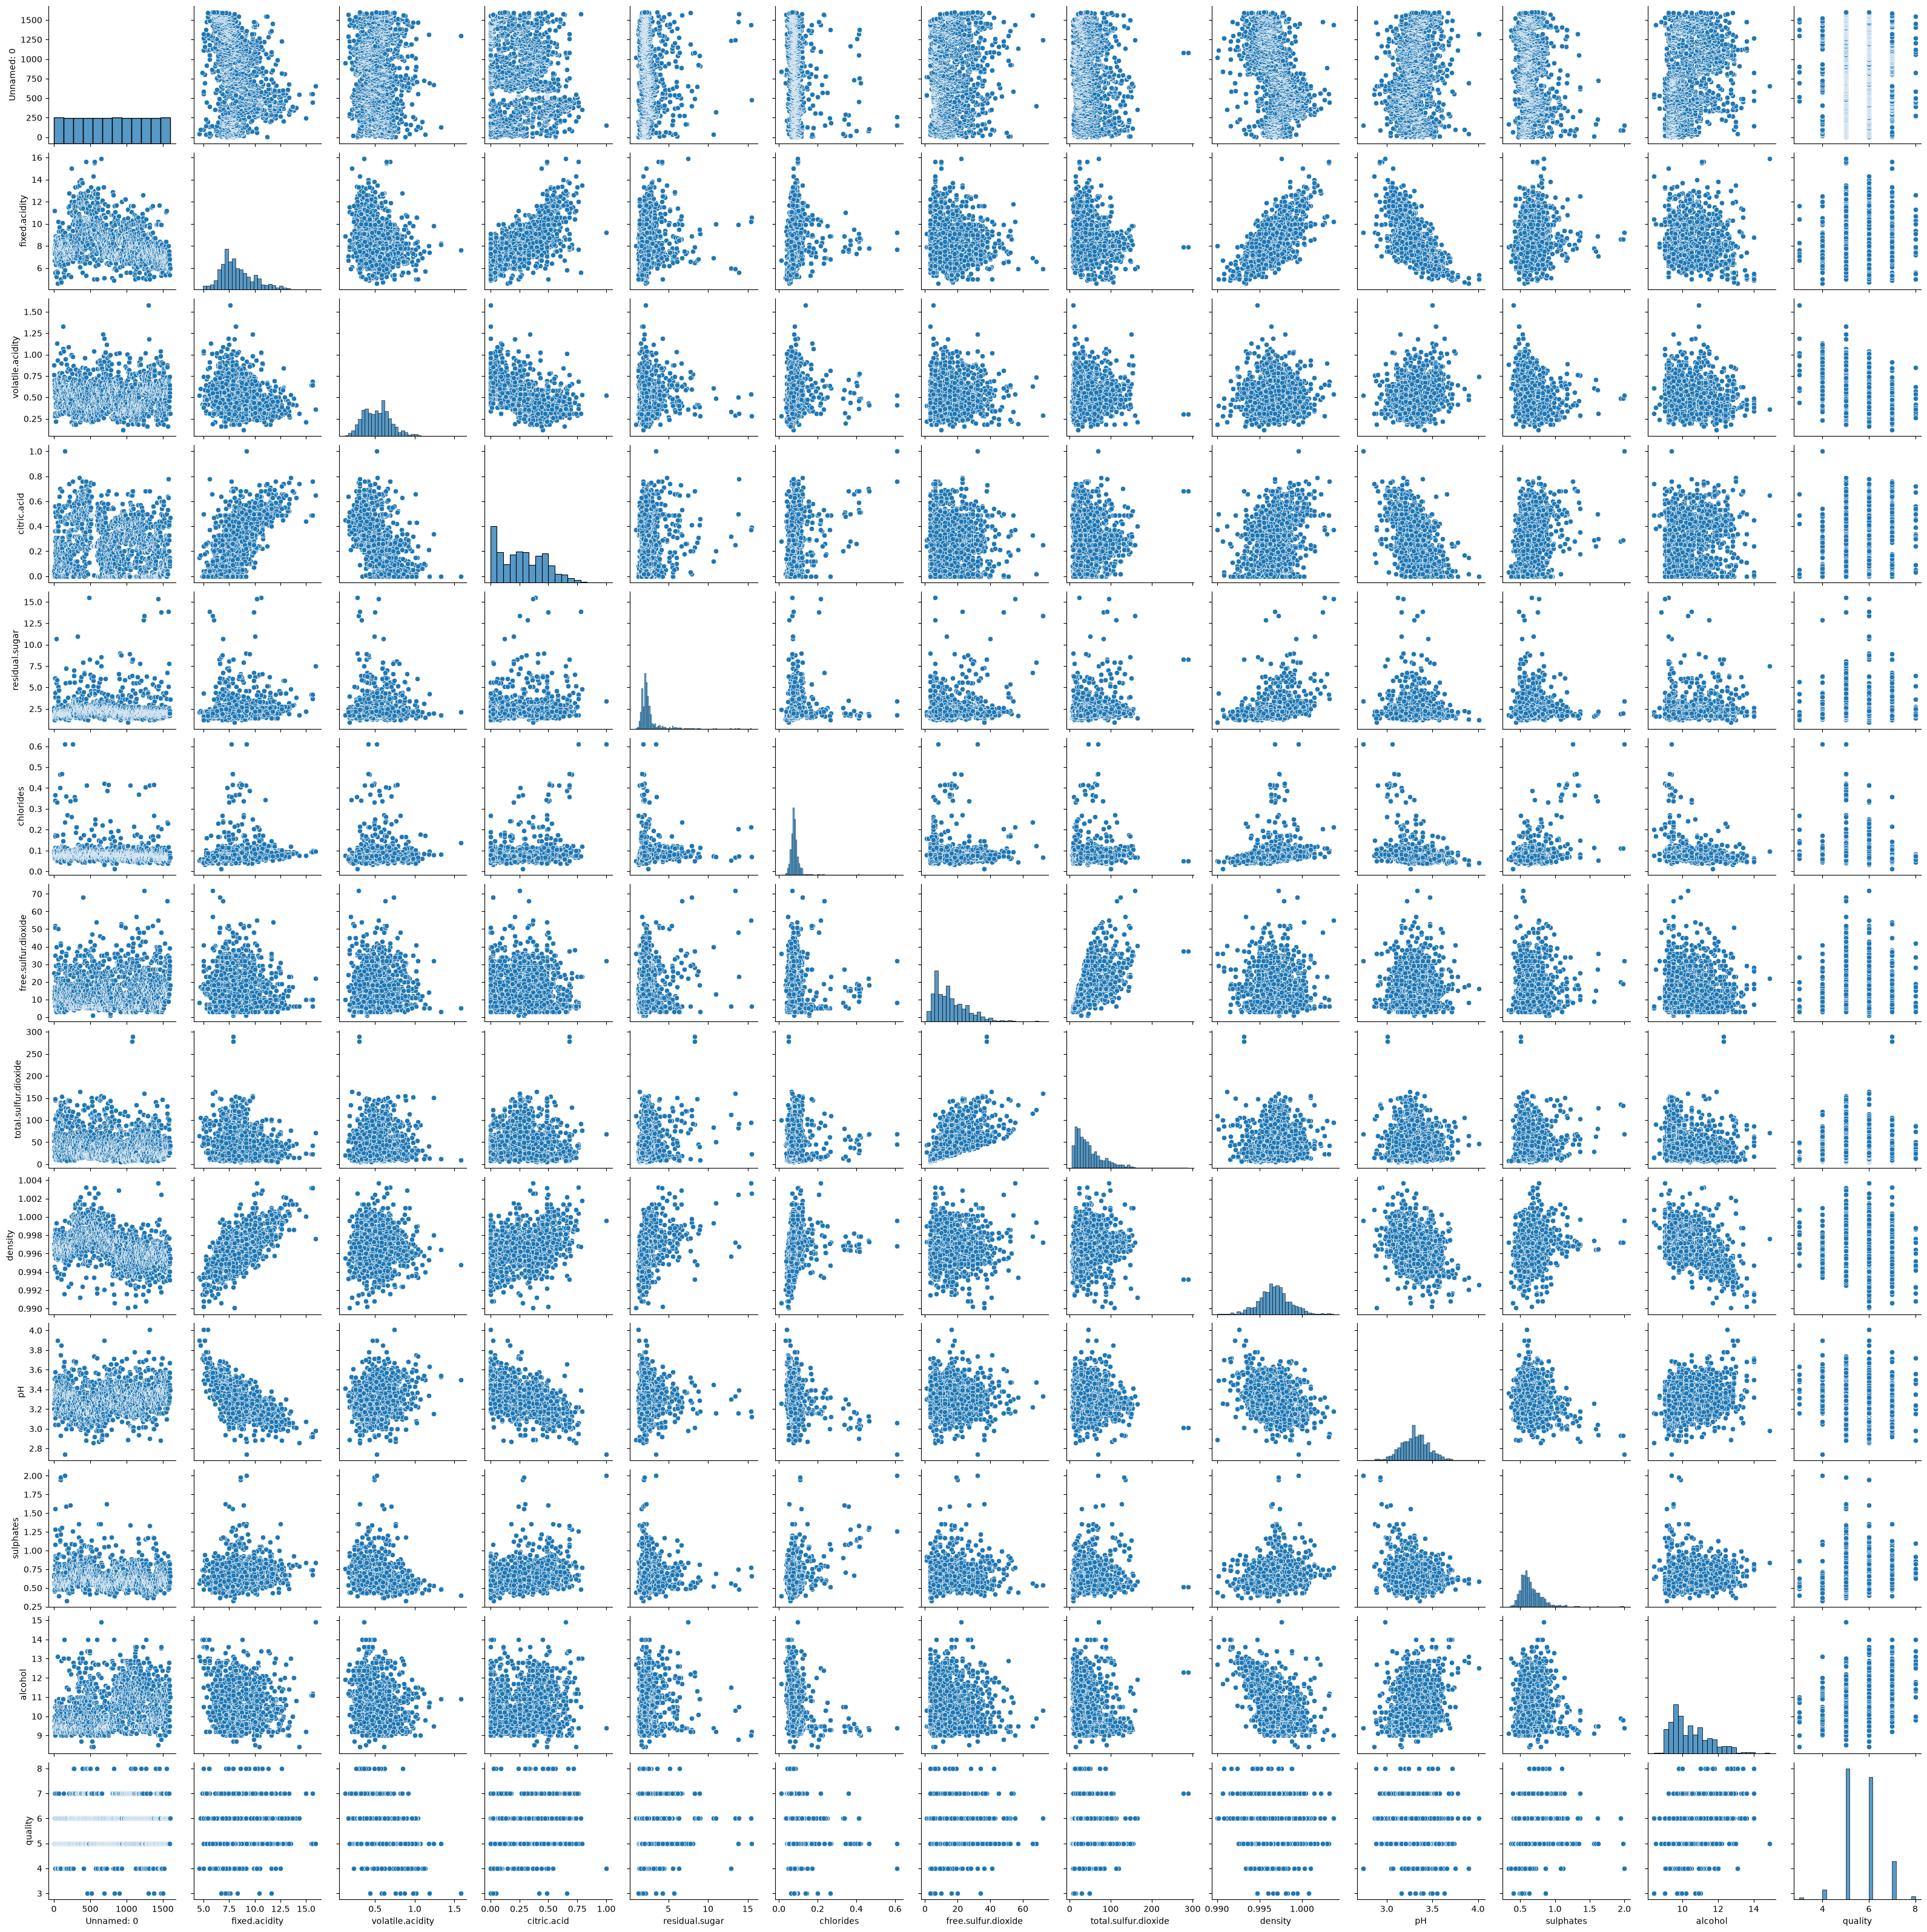

In [58]:
sns.pairplot(df)

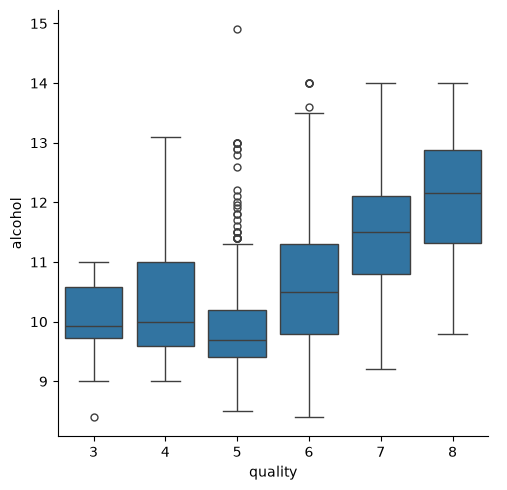

In [59]:
sns.catplot(x="quality",y="alcohol",data=df,kind="box")


<Axes: xlabel='alcohol', ylabel='pH'>

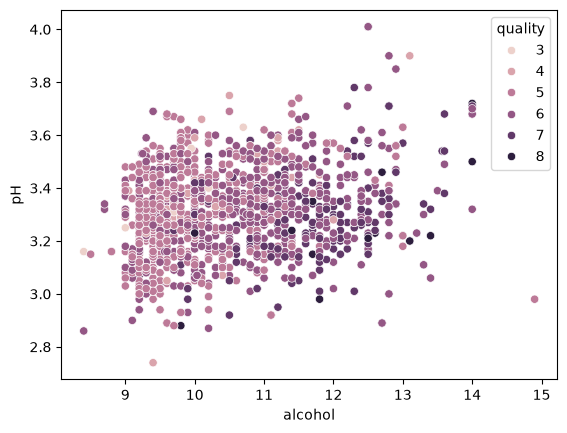

In [60]:
sns.scatterplot(x='alcohol',y='pH',hue='quality',data=df)

In [237]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\rushi\OneDrive\Documents\Machine_Learning\ML-Learnings
['.git', '.ipynb_checkpoints', 'env.txt', 'flight_price.xlsx', 'Untitled.ipynb', 'wineQualityInfo.txt', 'wineQualityReds.csv']


In [238]:
df=pd.read_excel('flight_price.xlsx')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 1.8 MB


In [239]:
df[df.duplicated()]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
683,Jet Airways,1/06/2019,Delhi,Cochin,DEL → NAG → BOM → COK,14:35,04:25 02 Jun,13h 50m,2 stops,No info,13376
1061,Air India,21/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,22:00,19:15 22 May,21h 15m,2 stops,No info,10231
1348,Air India,18/05/2019,Delhi,Cochin,DEL → HYD → BOM → COK,17:15,19:15 19 May,26h,2 stops,No info,12392
1418,Jet Airways,6/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,05:30,04:25 07 Jun,22h 55m,2 stops,In-flight meal not included,10368
1674,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,18:25,21:20,2h 55m,non-stop,No info,7303
...,...,...,...,...,...,...,...,...,...,...,...
10594,Jet Airways,27/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,12:35 28 Jun,13h 30m,2 stops,No info,12819
10616,Jet Airways,1/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,09:40,12:35 02 Jun,26h 55m,2 stops,No info,13014
10634,Jet Airways,6/06/2019,Delhi,Cochin,DEL → JAI → BOM → COK,09:40,12:35 07 Jun,26h 55m,2 stops,In-flight meal not included,11733
10672,Jet Airways,27/06/2019,Delhi,Cochin,DEL → AMD → BOM → COK,23:05,19:00 28 Jun,19h 55m,2 stops,In-flight meal not included,11150


In [240]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [241]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [242]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 1.8 MB


In [243]:
df['Date']=df['Date_of_Journey'].str.split("/").str[0]
print(df['Date'])

0        24
1         1
2         9
3        12
4        01
         ..
10678     9
10679    27
10680    27
10681    01
10682     9
Name: Date, Length: 10683, dtype: object


In [244]:
df['Month']=df['Date_of_Journey'].str.split("/").str[1]
df["Month"]

0        03
1        05
2        06
3        05
4        03
         ..
10678    04
10679    04
10680    04
10681    03
10682    05
Name: Month, Length: 10683, dtype: object

In [245]:
df["Year"]=df["Date_of_Journey"].str.split("/").str[2]
df["Year"]

0        2019
1        2019
2        2019
3        2019
4        2019
         ... 
10678    2019
10679    2019
10680    2019
10681    2019
10682    2019
Name: Year, Length: 10683, dtype: object

In [246]:
df.columns

Index(['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route',
       'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops',
       'Additional_Info', 'Price', 'Date', 'Month', 'Year'],
      dtype='str')

In [247]:
df["Date"]=df["Date"].astype(int)
df["Month"]=df["Month"].astype(int)
df["Year"]=df["Year"].astype(int)

In [248]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
 11  Date             10683 non-null  int64
 12  Month            10683 non-null  int64
 13  Year             10683 non-null  int64
dtypes: int64(4), str(10)
memory usage: 2.0 MB


In [249]:
df.drop("Date_of_Journey",axis=1,inplace=True)

In [250]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Source           10683 non-null  str  
 2   Destination      10683 non-null  str  
 3   Route            10682 non-null  str  
 4   Dep_Time         10683 non-null  str  
 5   Arrival_Time     10683 non-null  str  
 6   Duration         10683 non-null  str  
 7   Total_Stops      10682 non-null  str  
 8   Additional_Info  10683 non-null  str  
 9   Price            10683 non-null  int64
 10  Date             10683 non-null  int64
 11  Month            10683 non-null  int64
 12  Year             10683 non-null  int64
dtypes: int64(4), str(9)
memory usage: 1.9 MB


In [251]:
df["Arrival_Time"]

0        01:10 22 Mar
1               13:15
2        04:25 10 Jun
3               23:30
4               21:35
             ...     
10678           22:25
10679           23:20
10680           11:20
10681           14:10
10682           19:15
Name: Arrival_Time, Length: 10683, dtype: str

In [252]:
df["Arrival_Time"]=df["Arrival_Time"].apply(lambda x:x.split(' ')[0])
df["Arrival_Time"]

0        01:10
1        13:15
2        04:25
3        23:30
4        21:35
         ...  
10678    22:25
10679    23:20
10680    11:20
10681    14:10
10682    19:15
Name: Arrival_Time, Length: 10683, dtype: str

In [253]:
df["Arrival_hour"]=df["Arrival_Time"].str.split(':').str[0]
df["Arrival_hour"]

0        01
1        13
2        04
3        23
4        21
         ..
10678    22
10679    23
10680    11
10681    14
10682    19
Name: Arrival_hour, Length: 10683, dtype: object

In [254]:
df["Arrival_min"]=df["Arrival_Time"].str.split(':').str[1]
df["Arrival_min"]

0        10
1        15
2        25
3        30
4        35
         ..
10678    25
10679    20
10680    20
10681    10
10682    15
Name: Arrival_min, Length: 10683, dtype: object

In [255]:
df.drop('Arrival_Time',axis=1,inplace=True)

In [256]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  str   
 1   Source           10683 non-null  str   
 2   Destination      10683 non-null  str   
 3   Route            10682 non-null  str   
 4   Dep_Time         10683 non-null  str   
 5   Duration         10683 non-null  str   
 6   Total_Stops      10682 non-null  str   
 7   Additional_Info  10683 non-null  str   
 8   Price            10683 non-null  int64 
 9   Date             10683 non-null  int64 
 10  Month            10683 non-null  int64 
 11  Year             10683 non-null  int64 
 12  Arrival_hour     10683 non-null  object
 13  Arrival_min      10683 non-null  object
dtypes: int64(4), object(2), str(8)
memory usage: 1.9+ MB


In [257]:
df["Arrival_hour"]=df["Arrival_hour"].astype(int)

In [258]:
df["Arrival_min"]=df["Arrival_min"].astype(int)

In [259]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Source           10683 non-null  str  
 2   Destination      10683 non-null  str  
 3   Route            10682 non-null  str  
 4   Dep_Time         10683 non-null  str  
 5   Duration         10683 non-null  str  
 6   Total_Stops      10682 non-null  str  
 7   Additional_Info  10683 non-null  str  
 8   Price            10683 non-null  int64
 9   Date             10683 non-null  int64
 10  Month            10683 non-null  int64
 11  Year             10683 non-null  int64
 12  Arrival_hour     10683 non-null  int64
 13  Arrival_min      10683 non-null  int64
dtypes: int64(6), str(8)
memory usage: 1.9 MB


In [260]:
df['Dep_Time']

0        22:20
1        05:50
2        09:25
3        18:05
4        16:50
         ...  
10678    19:55
10679    20:45
10680    08:20
10681    11:30
10682    10:55
Name: Dep_Time, Length: 10683, dtype: str

In [261]:
df["Dep_hour"]=df["Dep_Time"].str.split(':').str[0]

In [262]:
df["Dep_minute"]=df["Dep_Time"].str.split(':').str[1]

In [263]:
df.drop('Dep_Time',axis=1,inplace=True)

In [264]:
df['Dep_hour']=df['Dep_hour'].astype(int)

In [265]:
df['Dep_minute']=df['Dep_minute'].astype(int)

In [266]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Source           10683 non-null  str  
 2   Destination      10683 non-null  str  
 3   Route            10682 non-null  str  
 4   Duration         10683 non-null  str  
 5   Total_Stops      10682 non-null  str  
 6   Additional_Info  10683 non-null  str  
 7   Price            10683 non-null  int64
 8   Date             10683 non-null  int64
 9   Month            10683 non-null  int64
 10  Year             10683 non-null  int64
 11  Arrival_hour     10683 non-null  int64
 12  Arrival_min      10683 non-null  int64
 13  Dep_hour         10683 non-null  int64
 14  Dep_minute       10683 non-null  int64
dtypes: int64(8), str(7)
memory usage: 1.9 MB


In [267]:
df.sample(2)

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dep_hour,Dep_minute
6105,Jet Airways,Kolkata,Banglore,CCU → BOM → BLR,28h 40m,1 stop,In-flight meal not included,8529,12,6,2019,23,35,18,55
8085,IndiGo,Mumbai,Hyderabad,BOM → HYD,1h 30m,non-stop,No info,4049,12,5,2019,7,55,6,25


In [268]:
df['Total_Stops'].unique()

<ArrowStringArray>
['non-stop', '2 stops', '1 stop', '3 stops', nan, '4 stops']
Length: 6, dtype: str

In [269]:
df[df['Total_Stops'].isnull()]

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dep_hour,Dep_minute
9039,Air India,Delhi,Cochin,NaN,23h 40m,NaN,No info,7480,6,5,2019,9,25,9,45


In [270]:
df['Total_Stops']=df['Total_Stops'].map({'non-stop':0,'2 stops':2,'1 stop':1,'3 stops':3,np.nan:1,'4 stops':4})

In [271]:
df['Total_Stops'].unique()

array([0, 2, 1, 3, 4])

In [272]:
df[df['Total_Stops'].isnull()]

,Airline,Source,Destination,Route,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dep_hour,Dep_minute


In [273]:
df["Route"]

0                    BLR → DEL
1        CCU → IXR → BBI → BLR
2        DEL → LKO → BOM → COK
3              CCU → NAG → BLR
4              BLR → NAG → DEL
                 ...          
10678                CCU → BLR
10679                CCU → BLR
10680                BLR → DEL
10681                BLR → DEL
10682    DEL → GOI → BOM → COK
Name: Route, Length: 10683, dtype: str

In [274]:
df.drop("Route",axis=1,inplace=True)

In [275]:
df['Duration']

0        2h 50m
1        7h 25m
2           19h
3        5h 25m
4        4h 45m
          ...  
10678    2h 30m
10679    2h 35m
10680        3h
10681    2h 40m
10682    8h 20m
Name: Duration, Length: 10683, dtype: str

In [283]:
df["Duration_hour"]=df["Duration"].str.split(" ").str[0].str.split("h").str[0]
df["Duration_hour"]

0         2
1         7
2        19
3         5
4         4
         ..
10678     2
10679     2
10680     3
10681     2
10682     8
Name: Duration_hour, Length: 10683, dtype: object

In [284]:
df["Duration_minute"]=df["Duration"].str.split(" ").str[1].str.split("m").str[0]

In [285]:
df["Duration_minute"] = df["Duration_minute"].fillna(0)

In [286]:
df["Duration_minute"]

0        50
1        25
2         0
3        25
4        45
         ..
10678    30
10679    35
10680     0
10681    40
10682    20
Name: Duration_minute, Length: 10683, dtype: object

In [236]:
df[df["Duration_hour"]=="5m"]

,Airline,Source,Destination,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dep_hour,Dep_minute,Duration_hour,Duration_minute
6474,Air India,Mumbai,Hyderabad,5m,2,No info,17327,6,3,2019,16,55,16,50,5m,0


In [288]:
df["Duration_hour"] = df["Duration"].str.extract(r'(\d+)h').fillna(0)
df["Duration_minute"] = df["Duration"].str.extract(r'(\d+)m').fillna(0)

df["Duration_hour"] = df["Duration_hour"].astype(int)
df["Duration_minute"] = df["Duration_minute"].astype(int)

- (\d+)h → extract number before h
- (\d+)m → extract number before m
- If h or m is missing, it returns NaN
- .fillna(0) converts missing hours/minutes to 0

In [290]:
df[df["Duration_hour"]=="5m"]

,Airline,Source,Destination,Duration,Total_Stops,Additional_Info,Price,Date,Month,Year,Arrival_hour,Arrival_min,Dep_hour,Dep_minute,Duration_hour,Duration_minute


In [291]:
df["Airline"].unique()

<ArrowStringArray>
[                           'IndiGo',                         'Air India',
                       'Jet Airways',                          'SpiceJet',
                 'Multiple carriers',                             'GoAir',
                           'Vistara',                          'Air Asia',
           'Vistara Premium economy',              'Jet Airways Business',
 'Multiple carriers Premium economy',                            'Trujet']
Length: 12, dtype: str

In [293]:
df['Source'].unique()

<ArrowStringArray>
['Banglore', 'Kolkata', 'Delhi', 'Chennai', 'Mumbai']
Length: 5, dtype: str

In [294]:
df["Additional_Info"].unique()

<ArrowStringArray>
[                     'No info',  'In-flight meal not included',
 'No check-in baggage included',              '1 Short layover',
                      'No Info',               '1 Long layover',
              'Change airports',               'Business class',
               'Red-eye flight',               '2 Long layover']
Length: 10, dtype: str

In [295]:
from sklearn.preprocessing import OneHotEncoder
encoder=OneHotEncoder()
encoder.fit_transform(df[["Airline","Source","Destination"]]).toarray()

array([[0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(10683, 23))

In [296]:
pd.DataFrame(encoder.fit_transform(df[["Airline","Source","Destination"]]).toarray(),columns=encoder.get_feature_names_out())

,Airline_Air Asia,Airline_Air India,Airline_GoAir,Airline_IndiGo,Airline_Jet Airways,Airline_Jet Airways Business,Airline_Multiple carriers,Airline_Multiple carriers Premium economy,Airline_SpiceJet,Airline_Trujet,...,Source_Chennai,Source_Delhi,Source_Kolkata,Source_Mumbai,Destination_Banglore,Destination_Cochin,Destination_Delhi,Destination_Hyderabad,Destination_Kolkata,Destination_New Delhi
0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
10679,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
10680,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
10681,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
